In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models


In [2]:
# 1. Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [3]:
# 2. Preprocess: Normalize pixel values from [0, 255] to [0.0, 1.0]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [4]:
# 3. Build the Artificial Neural Network (Multilayer Perceptron)
model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),  # Converts 28x28 image into a 784-element vector
    layers.Dense(128, activation="relu", name="Hidden_Layer_1"),
    layers.Dropout(0.2),  # Prevents overfitting
    layers.Dense(64, activation="relu", name="Hidden_Layer_2"),
    layers.Dense(10, activation="softmax", name="Output_Layer"),  # Digits 0-9
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:


# 4. Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)



In [6]:
# 5. Train the model
history = model.fit(
    x_train, y_train, epochs=8, batch_size=32, validation_split=0.1
)



Epoch 1/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - accuracy: 0.9115 - loss: 0.2983 - val_accuracy: 0.9685 - val_loss: 0.1108
Epoch 2/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - accuracy: 0.9565 - loss: 0.1408 - val_accuracy: 0.9763 - val_loss: 0.0842
Epoch 3/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9664 - loss: 0.1072 - val_accuracy: 0.9768 - val_loss: 0.0756
Epoch 4/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9716 - loss: 0.0906 - val_accuracy: 0.9800 - val_loss: 0.0711
Epoch 5/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9756 - loss: 0.0780 - val_accuracy: 0.9803 - val_loss: 0.0696
Epoch 6/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9794 - loss: 0.0656 - val_accuracy: 0.9813 - val_loss: 0.0621
Epoch 7/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.9795 - loss: 0.0633 - val_accuracy: 0.9798 - val_loss: 0.0693
Epoch 8/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9817 - loss: 0.0568 - v

In [7]:
# 6. Evaluate on unseen test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc * 100:.2f}% | Test Loss: {test_loss:.4f}")




Test Accuracy: 97.75% | Test Loss: 0.0797


In [8]:
# 7. Save the trained ANN model
model.save("mnist_ann_model.keras")
print("Model saved successfully as 'mnist_ann_model.keras'")



Model saved successfully as 'mnist_ann_model.keras'


Saved 'training_history.png' for your PPT/Report.


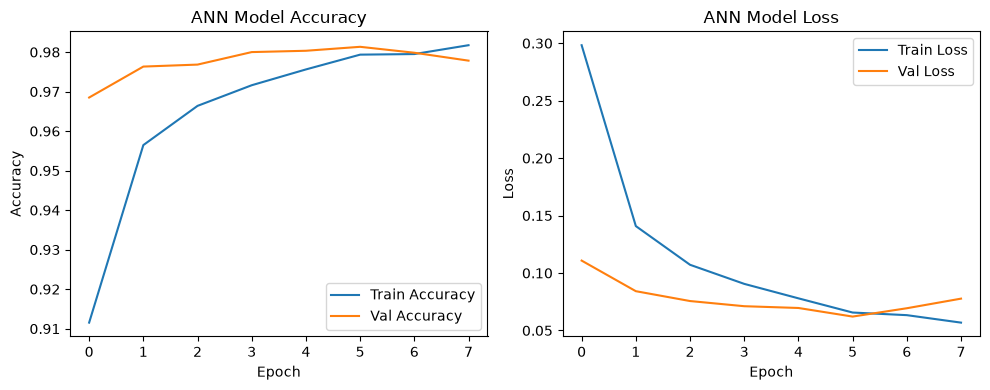

In [9]:
# 8. Save Accuracy & Loss Plot for PPT and Activity Report
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.title("ANN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("ANN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("training_history.png", dpi=300)
print("Saved 'training_history.png' for your PPT/Report.")